In [ ]:
import pandas as pd
import numpy as np
 

df = pd.read_csv('california_housing_data.csv')

df[ 'income_categories'] = pd.cut( df['median_income'] , bins=[ 0 ,2 ,4, 6 , 8, np.inf],
                                                      labels=[ 1 ,2 , 3, 4, 5 ] )

from sklearn.model_selection import StratifiedShuffleSplit
splitting = StratifiedShuffleSplit( n_splits = 1 , test_size = 0.2 , random_state = 42)
for train_split ,  test_split in splitting.split( df , df['income_categories'] ):
    train_data = df.loc[ train_split]
    test_data = df.loc[ test_split]

train_data ,test_data

## Deleting the Income_Catogary colum from test_data and train_data

In [20]:

train_data.drop( columns=['income_categories'] , inplace = True)  

# inplace = True means that the changes will be made in the original dataframe and not a copy of it

test_data.drop( columns=['income_categories'] , inplace = True)

# -------------------------------------------------------------------------


# 1.)       Visualizing the Data

### Before handling missing values or training models, it’s important to visualize the data to uncover patterns, relationships, and potential issues.

In [21]:

df = train_data.copy()

# taking a sample of 1000 data points for visualisation

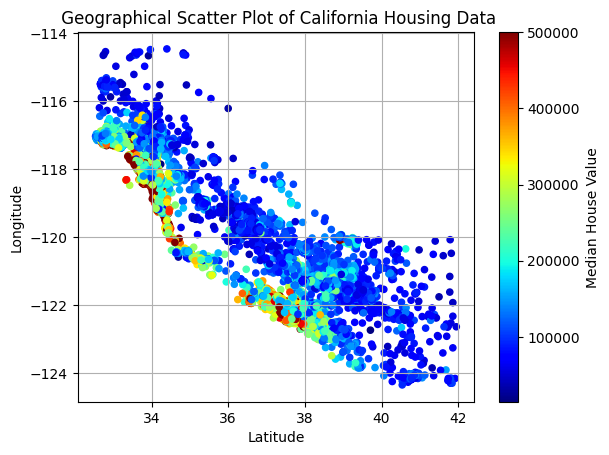

In [22]:


import matplotlib.pyplot as plt
import seaborn as sns


plt.title(" Geographical Scatter Plot of California Housing Data")
plt.xlabel( "Latitude" )
plt.ylabel("Longitude")

plt.grid(axis="both")



sc = plt.scatter( df['latitude'] , df['longitude'] ,
             
            c = df['median_house_value'] , cmap = "jet" ,  # color of scatter dots based on median house value - using "jet" colormap

            #alpha = 0.3 ,      # transparency/opacity - for better visibility of overlapping points - 
                                                        # more the value, more the transparency
            s = 20 ,           # size of scatter dots
           
            )
 
cbar = plt.colorbar(sc)
cbar.set_label("Median House Value")

plt.show()

# -------------------------------------------------------------------------


## 2.]  Correlation Matrix : 

Correlation coefficient is a statistical measure that quantifies the strength and direction of the relationship between two variables.


- It is a measure of how strongly two variables are related to each other. It ranges from -1 to 1, where:
1.  -1 indicates a perfect negative correlation (as one variable increases, the other decreases)
2.  0 indicates no correlation (the variables are independent of each other)
3.  1 indicates a perfect positive correlation (as one variable increases, the other also increases)

# NOTE : remove any string datatype col in df FOR CORRELATION

In [ ]:

df.drop( columns=['ocean_proximity'] , inplace = True , axis = 1)    

# dropping ocean_proximity column as it is categorical and we are interested in correlation between numerical attributes              
# axis = 1 means we are dropping a column and not a row
# inplace = True means that the changes will be made in the original dataframe and not a copy of it


In [ ]:
# Correlation Coefficient - measures the strength and direction of linear relationships between variables/columns in the dataset


correlation_coffeciant = df.corr()

correlation_coffeciant

Check how strongly each attribute correlates with the target:



In [32]:


correlation_coffeciant["median_house_value"].sort_values(ascending=False)



#This helps identify useful predictors. For example, median_income usually shows a strong positive correlation with house prices.

median_house_value    1.000000
median_income         0.688863
total_rooms           0.132373
housing_median_age    0.110525
households            0.062793
total_bedrooms        0.046086
population           -0.028369
longitude            -0.045430
latitude             -0.143982
Name: median_house_value, dtype: float64

# -------------------------------------------------------------------------



# 3.) SCATTER MATRIX 
to visualise the pairwise relationships between multiple numerical attributes in the dataset

#### 1.  The diagonal plots show the distribution of same 2 attribute,
#### 2.  while the off-diagonal plots show the scatter plots of the pairwise relationships between different attributes.
#### 3.  The color of the points in the scatter plots can be used to identify patterns and correlations between attributes.

array([[<Axes: xlabel='median_house_value', ylabel='median_house_value'>,
        <Axes: xlabel='median_income', ylabel='median_house_value'>,
        <Axes: xlabel='total_rooms', ylabel='median_house_value'>,
        <Axes: xlabel='housing_median_age', ylabel='median_house_value'>],
       [<Axes: xlabel='median_house_value', ylabel='median_income'>,
        <Axes: xlabel='median_income', ylabel='median_income'>,
        <Axes: xlabel='total_rooms', ylabel='median_income'>,
        <Axes: xlabel='housing_median_age', ylabel='median_income'>],
       [<Axes: xlabel='median_house_value', ylabel='total_rooms'>,
        <Axes: xlabel='median_income', ylabel='total_rooms'>,
        <Axes: xlabel='total_rooms', ylabel='total_rooms'>,
        <Axes: xlabel='housing_median_age', ylabel='total_rooms'>],
       [<Axes: xlabel='median_house_value', ylabel='housing_median_age'>,
        <Axes: xlabel='median_income', ylabel='housing_median_age'>,
        <Axes: xlabel='total_rooms', ylabel='housi

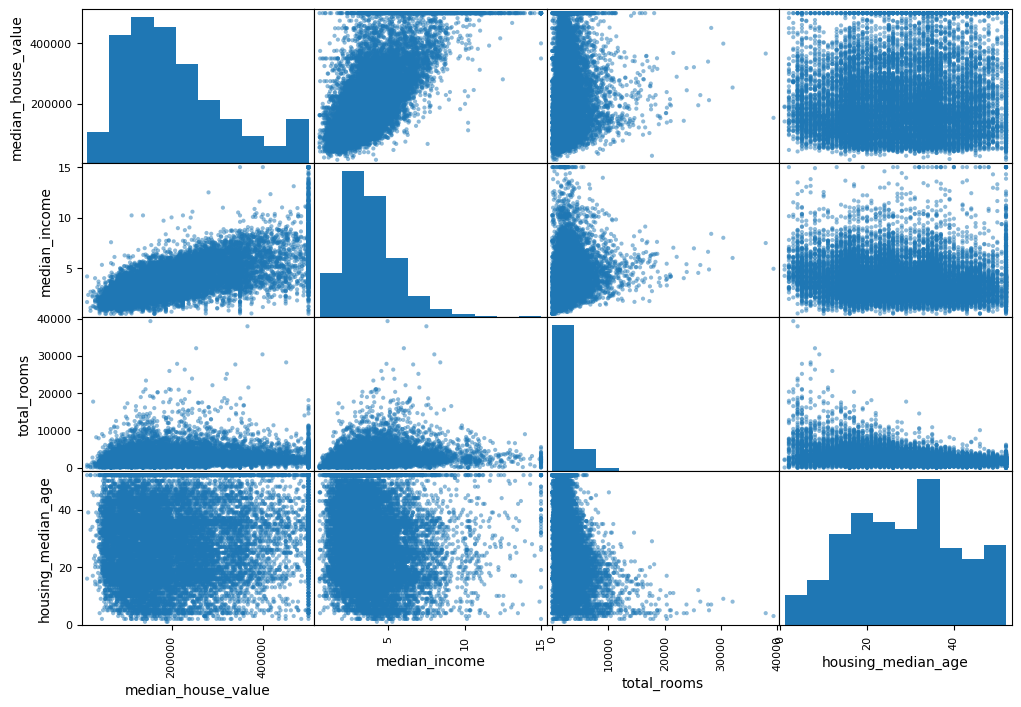

In [33]:



# SCATTER MATRIX - to visualise the pairwise relationships between multiple numerical attributes in the dataset

from pandas.plotting import  scatter_matrix


features = [ 'median_house_value' , 'median_income',  'total_rooms' , 'housing_median_age' ]


scatter_matrix( df[ features]  , figsize = (12 ,8) )

# The diagonal plots show the distribution of same 2 attribute,
#  while the off-diagonal plots show the scatter plots of the pairwise relationships between different attributes.
#  The color of the points in the scatter plots can be used to identify patterns and correlations between attributes.